# 생성형 AI를 활용한 제조결함 데이터 생성

과제 원본 코드(`8-2. 생성형 AI를 활용한 제조결함 데이터 생성_실습 (1).ipynb`)를 **흐름 단위로 묶어** 놓았다.
한 흐름을 끝까지 실행한 뒤, 그 아래 **✍️ 내 코멘트** 칸에 무엇을 했고 무엇을 알게 됐는지 적는다.

흐름마다 붙어 있는 칸
- **📖 코드 설명**: 코드가 무슨 일을 하는지
- **💡 생각해 볼 점**: 코드 리뷰할 때 짚어 볼 만한 부분 (원본 코드의 특이점, 개선할 여지)
- **✍️ 내 코멘트**: 직접 작성

**실행 전 확인 (코랩)**
- 메뉴 **런타임 → 런타임 유형 변경**에서 **GPU**를 고른다. 이번 실행은 코랩 Pro의 **A100**에서 했다(저장소 안내: GPU 메모리 30GB 미만에서 동작).
- 흐름 10의 PCB 셀은 `normal.png`를 읽는데, 이 파일은 AnomalyAny 저장소에 없다. 원본 노트북 출력에 남은 PCB 사진을 `normal.png`로 저장해 두었으니, 흐름 1을 실행한 뒤 코랩 **파일 패널**에 올리고 `/content/AnomalyAny/`로 옮긴다.
- 코드는 원본 그대로다. 코랩에서 그대로 안 되는 줄만 `# 📄 원본`과 `# ☁️ 코랩용`을 나란히 적었다.
- 시간이 오래 걸리는 셀: 결함 이미지 1장에 3\~4분(개인 실험 셀 출력 기준 187\~197초). 흐름 6(1장), 흐름 9(4장), 흐름 11(4장)을 합쳐 30\~40분 걸린다.
- 흐름 11 아래의 `🧪 [개인 실험]` 셀 두 개는 원본에 없는 셀이다. 각각 다른 날 따로 실행해서(필요한 준비 셀만 다시 실행) 실행 번호가 앞뒤 셀과 이어지지 않는다.
  - 실험 1(PCB에 맞는 결함 문장): 4장에 13분 정도 걸렸다.
  - 실험 2(PaDiM으로 채점): VisA 데이터셋(약 1.9GB)을 받아 PaDiM을 학습한다. 원본 셀이 생성 이미지를 저장하지 않아서, 위 출력 이미지 8장을 `gen/` 폴더에 올려 두고 읽는다.

## 🗺️ 전체 흐름 한눈에

| 파트 | 흐름 | 하는 일 |
|---|---|---|
| A. 준비 | 1\~3 | AnomalyAny 저장소 받기·설치 → 모듈 불러오기 → Stable Diffusion 파이프라인 불러오기 |
| B. 테이블: 색 바램 | 4\~7 | 프롬프트 3종과 정상 이미지 → 생성 함수 정의 → 결함 이미지 1장 생성 → 토큰별 주의 맵 |
| C. 헤이즐넛: 균열 | 8\~9 | 프롬프트와 정상 이미지 → 결함 이미지 4장 생성 |
| D. PCB: 균열 | 10\~11 | 프롬프트와 정상 이미지 → 결함 이미지 4장 생성 |

**왜 결함 이미지를 "만드는가"** (8-1 Stable Diffusion에 이어서)

공장에서 불량은 드물다. 정상 사진은 수천 장이어도 특정 결함 사진은 몇 장 없어서, 불량을 찾는 모델을 학습·평가하기 어렵다. **AnomalyAny**(CVPR 2025, EPFL)는 **정상 사진 1장 + 결함을 설명하는 문장**만으로, 추가 학습 없이 Stable Diffusion에서 그 결함이 있는 사진을 만들어 낸다.

```
정상 사진 1장 ─▶ 노이즈를 조금 섞음 ─▶ 디노이징 60스텝 (원래 200스텝 중 마지막 30%)
                                       │  매 스텝마다 10번씩 고쳐 나감
결함 문장 "… with a crack on it" ──────┤  ① 주의(attention) 손실: 'crack' 단어가 그림의 어딘가에 강하게 반영되게
자세한 문장 "… large, jagged crack …" ─┘  ② CLIP 손실: 결과 그림이 자세한 문장과 닮게 (후반 30%에서만)
                                       ▼
                                 결함 이미지 (512×512) + 'crack' 단어의 주의 맵
```

세 가지 문장의 역할

| 이름 | 예 (헤이즐넛) | 쓰이는 곳 |
|---|---|---|
| `prompt` | a photo of a hazelnut with a crack on it | 실제로 그림을 만드는 문장. 이 중 **8번째 단어**(`tokens = "8"`)를 집중 대상으로 삼는다 |
| `normal_prompt` | a photo of a hazelnut | 정상 기준. "정상 → 결함" 방향을 잡는 데 쓴다 |
| `detailed_prompt` | … with a large, jagged crack exposing the interior. | 결함을 자세히 풀어 쓴 문장. 결함 단어의 임베딩과 CLIP 손실이 이 문장 쪽으로 끌려간다 |

# 파트 A. 준비

## 흐름 1. AnomalyAny 저장소 받기와 작업 폴더 이동
논문 저자들의 코드를 통째로 받아 오고, 그 폴더로 들어간다. 이후 셀의 `from run import …` 같은 import는 이 폴더의 파일을 읽는다.

**📖 코드 설명**
- `git clone`: 저장소를 `/content/AnomalyAny`로 받는다. 안에는 생성 파이프라인(`clip_pipeline_attend_and_excite.py`), 실행 함수(`run.py`), 시각화(`utils/`), 예시 이미지(`example_web/table.jpg`, `example_image/000.png`)가 있다.
- `os.chdir('AnomalyAny')`: 작업 폴더를 옮긴다. 다시 실행하면 이미 안에 있으므로 `FileNotFoundError`가 난다.
- ☁️ 설치 줄: 원본에는 없다. 원본은 강사 서버의 conda 환경에서 돌려서 패키지가 이미 깔려 있었다.

In [1]:
!git clone https://github.com/EPFL-IMOS/AnomalyAny
# 📄 원본: (설치 줄 없음)
# ☁️ 코랩용: run.py의 pyrallis와 clip_loss.py의 OpenAI CLIP(clip)이 코랩에 없어서 설치.
#            코랩 기본 transformers 5.x에는 CLIPFeatureExtractor가 없어서 4.x로, 그에 맞춰 diffusers도 0.30.3으로 낮춤
!pip install pyrallis git+https://github.com/openai/CLIP.git "transformers<5" "diffusers==0.30.3"

Cloning into 'AnomalyAny'...
remote: Enumerating objects: 87, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (15/15), done.
remote: Total 87 (delta 26), reused 19 (delta 19), pack-reused 53 (from 1)
Receiving objects: 100% (87/87), 17.84 MiB | 18.36 MiB/s, done.
Resolving deltas: 100% (29/29), done.
  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-nxhf842h
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-nxhf842h
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 112.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 146.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 39.9 MB/s eta 0:00:00
   ━━━━━━

In [2]:
import os
os.chdir('AnomalyAny')
print("현재 디렉토리:", os.getcwd())

현재 디렉토리: /content/AnomalyAny


**Reference:** 이 코드는 EPFL-IMOS의 [AnomalyAny GitHub 리포지토리](https://github.com/EPFL-IMOS/AnomalyAny)에서 가져왔습니다.

**💡 생각해 볼 점**
- 원본은 `env.yml`(diffusers 0.21, transformers 4.29) 기준으로 짜였는데, 코랩에는 diffusers 0.40, transformers 5.18이 깔려 있다. `CLIPFeatureExtractor`처럼 이름이 사라진 것 때문에 import부터 막혀서, **두 라이브러리를 함께** 낮춰야 했다(transformers만 낮추면 diffusers와 huggingface-hub 버전이 충돌).
- 남이 만든 연구 코드는 라이브러리 버전을 정확히 고정해 두지 않으면, 시간이 조금만 지나도 그대로 돌지 않는다.

> ✍️ **내 코멘트**
>
> 저장소를 받고 코랩에 없는 pyrallis·clip을 설치했다. 연구 코드는 라이브러리 버전에 민감해서, 코랩 기본 버전으로는 import부터 막히고 버전을 맞춰야 돌아간다는 것을 알게 됐다.

## 흐름 2. 모듈 불러오기
저장소의 생성 파이프라인, 실행 함수, 시각화 도구를 불러온다.

**📖 코드 설명**
- `RelationalAttendAndExcitePipeline`: Stable Diffusion 파이프라인을 고쳐 만든 AnomalyAny 본체. 이름처럼 **Attend-and-Excite**(문장 속 특정 단어가 그림에 확실히 나타나도록 주의 맵을 키우는 기법)를 바탕으로 한다.
- `RunConfig`: 스텝 수, 가이던스 크기 같은 설정을 담는 데이터 클래스.
- `run_on_prompt_and_masked_image`: 정상 이미지(와 선택적으로 마스크)를 받아 결함 이미지를 만드는 함수. 흐름 5에서 쓴다.
- `AttentionStore`, `show_cross_attention_binary`, `vis_utils`: 생성 중 단어별 주의 맵을 모아 두고 그려 주는 도구.
- ☁️ `%load_ext autoreload`: 코랩의 Python 3.13에서 에러가 나서 주석 처리했다.

In [3]:
from typing import List, Dict
import torch

import sys
sys.path.append(".")
sys.path.append("..")

from clip_pipeline_attend_and_excite import RelationalAttendAndExcitePipeline
from config import RunConfig
from run import run_on_prompt, get_indices_to_alter, run_on_prompt_and_image, run_on_prompt_and_masked_image
from utils import vis_utils
from utils.ptp_utils import AttentionStore, show_cross_attention_binary

from utils.vis_utils import vis_ann

from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"

# 📄 원본: %load_ext autoreload
# 📄 원본: %autoreload 2
# ☁️ 코랩용: 코랩(Python 3.13)에는 imp 모듈이 없어 autoreload가 에러를 냄. 코드를 고칠 때 다시 불러오는 개발용 기능이라 주석 처리
# %load_ext autoreload
# %autoreload 2

**💡 생각해 볼 점**
- `run_on_prompt`, `get_indices_to_alter`, `run_on_prompt_and_image`, `vis_ann`은 불러오기만 하고 이 노트북에서 쓰지 않는다. `device`도 다음 셀에서 다시 정의된다.
- `autoreload`는 저장소 파일을 고치면서 실험할 때 쓰는 개발용 설정이라, 빼도 결과는 같다.

> ✍️ **내 코멘트**
>
> 생성 파이프라인과 시각화 도구를 불러왔다. 실제로 쓰는 것은 파이프라인, 설정, 실행 함수, 주의 맵 도구 정도이고, 나머지 import와 autoreload는 빠져도 결과에 영향이 없다는 것을 알게 됐다.

## 흐름 3. Stable Diffusion 파이프라인 불러오기
Stable Diffusion v1.5 가중치를 받아 AnomalyAny 파이프라인으로 GPU에 올린다.

**📖 코드 설명**
- `NUM_DIFFUSION_STEPS = 200`: 디노이징을 200단계로 나눈다(SD 기본값 50보다 촘촘). 단, 흐름 6에서 보듯 실제로는 마지막 60단계만 돈다.
- `GUIDANCE_SCALE = 12.5`: 문장을 얼마나 강하게 따를지(CFG). SD 기본값 7.5보다 크다.
- `MAX_NUM_WORDS = 77`: CLIP 텍스트 인코더가 받는 최대 토큰 수. 이 노트북에서는 쓰지 않는다.
- `safety_checker=None`: 유해 이미지 필터를 끈다. 출력의 경고문이 그 안내다.
- 모델 주소 `runwayml/stable-diffusion-v1-5`: 지금은 같은 가중치가 `stable-diffusion-v1-5/stable-diffusion-v1-5`로 옮겨졌지만, 옛 주소로 요청해도 새 주소로 자동 연결돼서 원본 줄 그대로 불러와진다(코랩에서 확인).

In [4]:
NUM_DIFFUSION_STEPS = 200
GUIDANCE_SCALE = 12.5
MAX_NUM_WORDS = 77
device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
stable = RelationalAttendAndExcitePipeline.from_pretrained("runwayml/stable-diffusion-v1-5", safety_checker=None).to(device)
tokenizer = stable.tokenizer

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'clip_pipeline_attend_and_excite.RelationalAttendAndExcitePipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


**💡 생각해 볼 점**
- 처음에는 runwayml 저장소가 사라진 줄 알고 실행해 보지도 않고 미러 주소로 바꿨다. 다시 확인해 보니 원본 주소도 새 주소로 자동 연결돼서 그대로 돌아갔고, 원본 줄로 되돌렸다. 고치기 전에 원본이 정말 안 되는지 먼저 돌려 봐야 한다.
- 모델 주소를 코드에 그대로 박아 두면, 저장소가 옮겨지거나 사라질 때 코드가 멈출 수 있다. 이번에는 Hugging Face가 옛 주소를 연결해 줘서 문제가 없었다.

> ✍️ **내 코멘트**
>
> SD v1.5를 200스텝, 가이던스 12.5로 설정해 불러왔다. 저장소가 사라진 줄 알고 실행해 보지 않은 채 주소를 바꿨는데 원본 주소도 그대로 돌아가서, 고치기 전에 원본이 정말 안 되는지 먼저 확인해야 한다는 것을 알게 됐다.

# 파트 B. 테이블: 색 바램(faded)

## 흐름 4. 프롬프트 3종과 정상 이미지 준비
"햇빛에 바랜 탁자"를 만들기 위해 문장 세 개를 정하고, 기준이 될 정상 탁자 사진을 불러온다.

**📖 코드 설명**
- `type = "table"`: 문장에 끼워 넣을 물체 이름. (파이썬 내장 함수 `type`을 덮어쓴다.)
- `tokens = "8"`: `prompt`에서 집중할 단어의 위치. `a(1) photo(2) of(3) a(4) table(5) that(6) is(7) faded(8)` → 8번이 `faded`다.
- `prompt` / `normal_prompt` / `detailed_prompt`: 맨 위 표의 세 문장.
- `thumbnail((768, 768))`: 가로세로 비율을 지키며 768 이하로 줄인다. 이미 작은 사진은 그대로 둔다.
- ☁️ `show()` → `display()`: 코랩에서는 `show()`가 셀 아래에 그림을 띄우지 않아서 바꿨다.

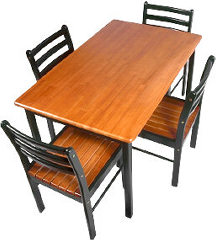

In [5]:
from PIL import Image

type = "table"
tokens = "8"
prompt = f"a photo of a {type} that is faded"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with areas of discoloration or lightening due to prolonged sun exposure"

root_path = f"./example_web/"
image_guidance_path = root_path + "table.jpg"


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
# 📄 원본: image_guidance.show()
# ☁️ 코랩용: 코랩에서는 PIL의 show()가 셀 아래에 이미지를 띄우지 않아서 display()로 바꿈
display(image_guidance)

**💡 생각해 볼 점**
- 토큰 번호 `"8"`을 손으로 적는다. 문장을 바꾸면 번호도 다시 세야 하고, 틀리면 엉뚱한 단어(예: `is`)에 집중하게 된다. 흐름 6 출력의 `Altering tokens: ['faded']`로 맞는지 확인할 수 있다.
- `original_size`는 저장만 하고 쓰지 않는다. 생성 결과는 512×512로 나오므로, 원래 크기로 되돌리려면 이 값을 써야 한다.

> ✍️ **내 코멘트**
>
> 정상 탁자 사진과 문장 세 개를 준비했다. 집중할 단어를 번호로 직접 지정하므로, 문장을 바꿀 때는 출력의 `Altering tokens`로 번호가 맞는지 확인해야 한다는 것을 알게 됐다.

## 흐름 5. 생성 함수 `run_and_display` 정의
설정을 `RunConfig`로 묶고, AnomalyAny 파이프라인을 한 번 돌려 결함 이미지를 돌려주는 함수를 만든다.

**📖 코드 설명**
- `RunConfig(...)`: 스텝 수(200), 가이던스(12.5), 주의 맵을 키우는 세기(`scale_factor`), 스텝별 목표치(`thresholds`)를 담는다.
- `run_on_prompt_and_masked_image(...)`: 실제 생성. 안에서 하는 일은 맨 위 그림과 같다.
  - `init_image`: 정상 사진에서 출발한다(처음부터 노이즈로 그리지 않음).
  - `init_image_guidance_scale`: 정상 사진을 얼마나 남길지. 0.3이면 200스텝 중 **마지막 30%(60스텝)만** 돌린다. 클수록 사진이 많이 바뀐다.
  - `mask_image`: 결함을 넣을 영역. `None`이면 사진 전체가 바뀔 수 있다.
- `display_output=True`면 결과 이미지를 셀 아래에 보여 준다.

In [6]:
def run_and_display(prompts: List[str],
                    controller: AttentionStore,
                    indices_to_alter: List[int],
                    init_image: Image.Image,
                    init_image_guidance_scale: float,
                    mask_image: str,
                    generator: torch.Generator,
                    run_standard_sd: bool = False,
                    scale_factor: int = 20,
                    thresholds: Dict[int, float] = {0: 0.05, 10: 0.5, 20: 0.8},
                    max_iter_to_alter: int = 25,
                    display_output: bool = False,
                    normal_prompt=normal_prompt,
                    detailed_prompt=detailed_prompt):
    config = RunConfig(prompt=prompts[0],
                       run_standard_sd=run_standard_sd,
                       scale_factor=scale_factor,
                       thresholds=thresholds,
                       max_iter_to_alter=max_iter_to_alter,
                       n_inference_steps=NUM_DIFFUSION_STEPS,
                       guidance_scale=GUIDANCE_SCALE)
    image, image_latent = run_on_prompt_and_masked_image(model=stable,
                          prompt=prompts,
                          controller=controller,
                          token_indices=indices_to_alter,
                          init_image=init_image,
                          init_image_guidance_scale=init_image_guidance_scale,
                          mask_image=mask_image,
                          seed=generator,
                          config=config,
                          normal_prompt=normal_prompt,
                          detailed_prompt=detailed_prompt)
    if display_output:
        display(image)
    return image, image_latent

**💡 생각해 볼 점**
- 기본값 `normal_prompt=normal_prompt, detailed_prompt=detailed_prompt`는 **함수를 정의할 때의 값(탁자 문장)** 으로 고정된다. 뒤에서 헤이즐넛·PCB로 문장을 바꿔도 기본값은 탁자 그대로라서, 호출할 때마다 직접 넘겨 줘야 한다(원본은 매번 넘겨서 문제가 없다).
- 파이프라인 안에서 CLIP 모델(ViT-L/14)을 **호출할 때마다 새로 불러온다**. 이미지를 여러 장 만들면 같은 모델을 반복해서 올리는 셈이다.

> ✍️ **내 코멘트**
>
> 설정을 묶어 파이프라인을 한 번 돌리는 함수를 만들었다. 정상 사진을 얼마나 남길지(`init_image_guidance_scale`)와 바꿀 영역(`mask_image`)이 결과를 좌우하는 핵심 인자라는 것을 알게 됐다.

## 흐름 6. 결함 이미지 생성 (테이블 1장)
무작위 시드 하나로 색 바랜 탁자를 만들고, `faded` 단어가 그림의 어디에 주의를 두었는지 겹쳐 본다.

# Anomaly Generation

**📖 코드 설명**
- `seeds = [random.randint(0, 100000)]`: 시드를 무작위로 하나 뽑는다. 실행할 때마다 다른 그림이 나온다.
- `get_indices_to_alter_new(...)`: 문장의 토큰 번호표를 출력하고(`{1: 'a', …, 8: 'faded'}`), 집중할 단어를 확인한다.
- `torch.Generator('cuda').manual_seed(seed)`: 노이즈를 시드로 고정한다.
- `AttentionStore()`: 생성하는 동안 단어별 주의 맵을 모아 둔다.
- `vis_utils.show_cross_attention(...)`: 집중 단어(`faded`)의 주의 맵을 결과 그림 위에 열지도로 겹쳐 보여 준다(빨갈수록 주의가 큼).
- `compute_time`: 장마다 걸린 시간을 모은다.

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'table',
 6: 'that',
 7: 'is',
 8: 'faded'}
Altering tokens: ['faded']


100%|███████████████████████████████████████| 890M/890M [00:13<00:00, 69.4MiB/s]
100%|████████████████████████████████████████| 244M/244M [00:01<00:00, 213MiB/s]
/content/AnomalyAny/clip_pipeline_attend_and_excite.py:712: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  num_channels_latents = self.unet.in_channels


  0%|          | 0/200 [00:00<?, ?it/s]

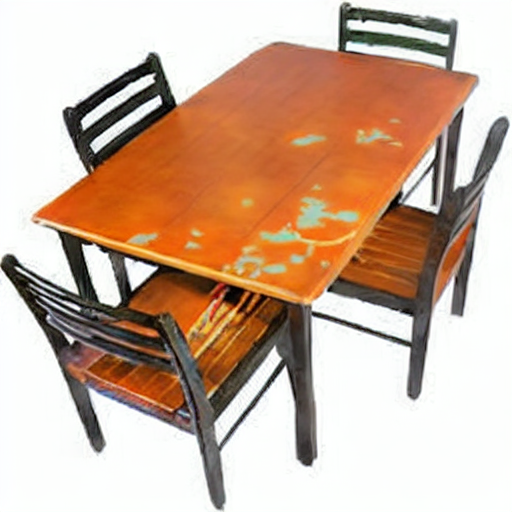

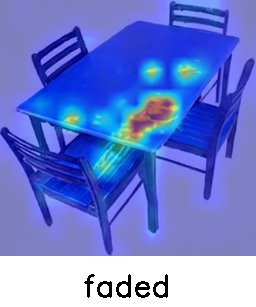

In [7]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))

    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

**🔎 실행 결과 읽기**
- 토큰 번호표에서 8번이 `faded`로 나오고 `Altering tokens: ['faded']`가 찍혔다 → 집중 대상이 맞게 잡혔다.
- 진행 표시줄은 `61/200`(30%)에서 끝난다. 오류가 아니라 `init_image_guidance_scale=0.3`이라 마지막 60스텝만 돌기 때문이다.
- 결과 그림(512×512): 탁자와 의자의 모양, 배치, 색은 정상 사진과 거의 같고, **상판에 희끗한 하늘색 얼룩**이 여기저기 생겼다. 의자 앞쪽에도 긁힌 듯한 자국이 생겼다.
- 주의 맵(열지도): `faded`의 주의가 **상판 가운데**에 몰려 빨갛게 나타나고, 얼룩이 생긴 자리와 대체로 겹친다.

**💡 생각해 볼 점**
- "햇빛에 바래 전체가 옅어진" 모습보다는 **얼룩이나 칠이 벗겨진 자국**에 가깝다. 문장이 뜻하는 결함과 실제로 그려진 결함이 다를 수 있으니, 만든 데이터는 사람이 보고 골라야 한다.
- 시드를 `random`으로 뽑고 출력하지 않아서, 마음에 드는 결과가 나와도 **같은 그림을 다시 만들 수 없다**. `print(seed)`를 남기거나 고정 시드를 쓰는 편이 좋다.
- `compute_time`에 장마다 걸린 시간을 모으지만 출력하지 않는다(시간을 찍는 `print`도 주석 처리되어 있다).
- `mask_image=None`이라 결함이 들어갈 자리를 정하지 않았다. 그래서 상판뿐 아니라 의자에도 자국이 생겼다.

> ✍️ **내 코멘트**
>
> 정상 탁자 사진 1장과 문장만으로, 모양은 그대로 둔 채 상판에 얼룩진 결함 이미지를 만들었다. 결함 단어의 주의가 몰린 자리에 결함이 생기지만, 문장 그대로의 결함(햇빛에 바램)이 나오지는 않을 수 있어서 사람이 골라내야 한다는 것을 알게 됐다.

## 흐름 7. 토큰별 주의 맵 보기
흐름 6에서 모아 둔 주의 맵을 문장의 **모든 단어**에 대해 흑백으로 그린다(밝을수록 그 단어가 그 자리에 영향을 크게 줌).

**📖 코드 설명**
- `show_cross_attention_binary(...)`: 16×16 해상도의 주의 맵을 단어마다 256×256으로 키워 나란히 보여 준다. `<|startoftext|>`, `<|endoftext|>`는 문장의 시작과 끝을 나타내는 특수 토큰이다.
- 원본 셀 다음의 빈 셀도 원본 그대로 두었다.

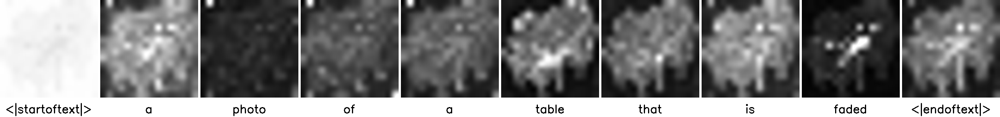

In [8]:
images, attention_maps = show_cross_attention_binary(controller, tokenizer, prompts, res=16, from_where=("up", "mid", "down"))

**🔎 실행 결과 읽기**
- `table`의 맵은 **탁자 전체 모양**을 따라 밝다 → 물체 단어는 물체 전체에 주의를 둔다.
- `faded`의 맵은 대부분 어둡고 **상판 가운데 일부만** 밝다 → 결함 단어의 주의가 좁은 영역에 모였고, 그 자리에 얼룩이 생겼다.
- `a`, `of`, `is` 같은 기능어와 `<|endoftext|>`도 물체 윤곽을 따라 밝게 나온다. `<|startoftext|>`는 전체가 고르게 밝아서 특정 위치 정보를 주지 않는다.

**💡 생각해 볼 점**
- 결함 단어의 주의 맵이 "결함이 어디에 생길지"를 미리 보여 주므로, 이 맵을 임계값으로 잘라 **결함 위치 마스크**(이상 탐지의 정답 마스크)로 쓸 수 있다. 이상 탐지 학습에는 사진뿐 아니라 이런 픽셀 단위 정답도 필요하다.
- 이 셀은 마지막으로 만든 이미지 1장의 주의 맵만 그린다. 테이블 부분에서만 실행하고 헤이즐넛·PCB에는 없다.

> ✍️ **내 코멘트**
>
> 단어마다 주의 맵을 그려 보니 물체 단어는 물체 전체를, 결함 단어는 좁은 한 곳을 비췄다. 결함 단어의 주의 맵이 곧 결함 위치를 알려 주므로, 결함 이미지와 함께 위치 정답(마스크)도 얻을 수 있다는 것을 알게 됐다.

# 파트 C. 헤이즐넛: 균열(crack)

## 흐름 8. 헤이즐넛 프롬프트와 정상 이미지
같은 방법을 MVTec AD 데이터셋의 헤이즐넛 사진에 적용한다. 결함은 "금이 간(crack)" 것이다.

**📖 코드 설명**
- `prompt = "a photo of a hazelnut with a crack on it"`: `a(1) photo(2) of(3) a(4) hazelnut(5) with(6) a(7) crack(8) …` → 8번이 `crack`이라 `tokens = "8"`이 그대로 맞는다.
- `detailed_prompt`: "속이 드러날 만큼 크고 들쭉날쭉한 균열".
- `image_num = str('000')`: 저장소의 `example_image/000.png`(헤이즐넛 정상 사진)를 읽는다.
- ☁️ `show()` → `display()`

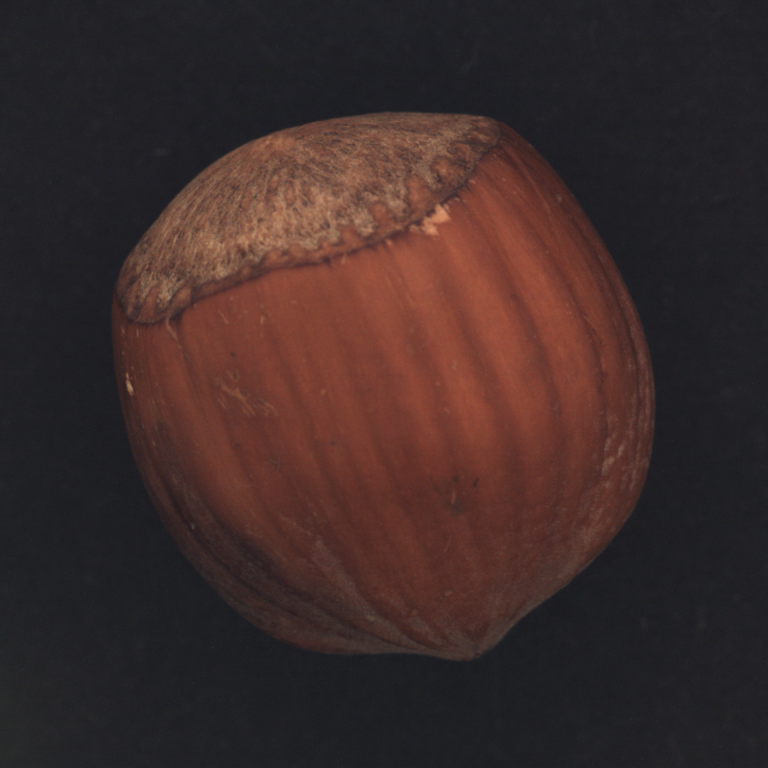

In [9]:
from PIL import Image

type = "hazelnut"
tokens = "8"
prompt = f"a photo of a {type} with a crack on it"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with a large, jagged crack exposing the interior."

image_num = str('000')
root_path = f"./example_image/"
image_guidance_path = root_path + image_num + '.png'


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
# 📄 원본: image_guidance.show()
# ☁️ 코랩용: 코랩에서는 PIL의 show()가 셀 아래에 이미지를 띄우지 않아서 display()로 바꿈
display(image_guidance)

**💡 생각해 볼 점**
- 헤이즐넛 사진은 이미 768×768이라 `thumbnail`로 줄어들지 않는다. 생성할 때는 다시 512×512로 바뀐다.
- 흐름 4의 셀을 거의 그대로 복사했다. 물체마다 바뀌는 것은 `type`, 문장, 사진 경로뿐이라 함수 하나로 묶을 수 있다.

> ✍️ **내 코멘트**
>
> 헤이즐넛 정상 사진과 균열 문장을 준비했다. `crack`이 마침 8번째 단어라 `tokens = "8"`을 그대로 쓸 수 있었고, 물체가 바뀌어도 바뀌는 건 이름·문장·경로뿐이라는 것을 알게 됐다.

## 흐름 9. 헤이즐넛 결함 이미지 4장 생성
시드 4개로 균열이 생긴 헤이즐넛을 4장 만든다. 코드는 흐름 6과 같고 `seeds`만 4개다.

**📖 코드 설명**
- `seeds = [random.randint(0, 100000), …]`: 무작위 시드 4개. 장마다 다른 노이즈에서 출발하므로 균열 모양과 위치가 달라진다.
- 반복문 안은 흐름 6과 같다: 생성 → 결과 출력 → `crack` 주의 맵 겹쳐 보기.

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'hazelnut',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']


  0%|          | 0/200 [00:00<?, ?it/s]

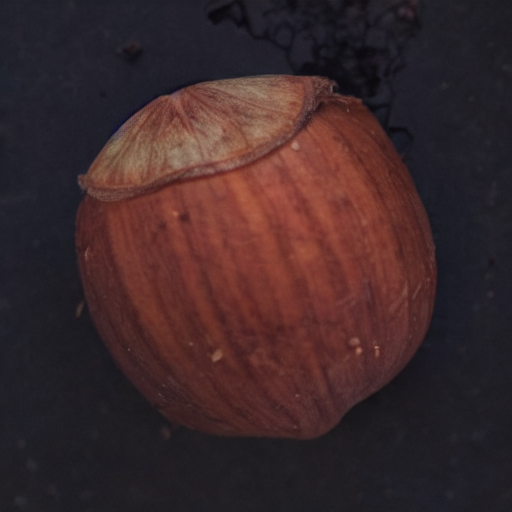

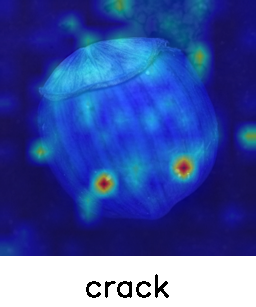

  0%|          | 0/200 [00:00<?, ?it/s]

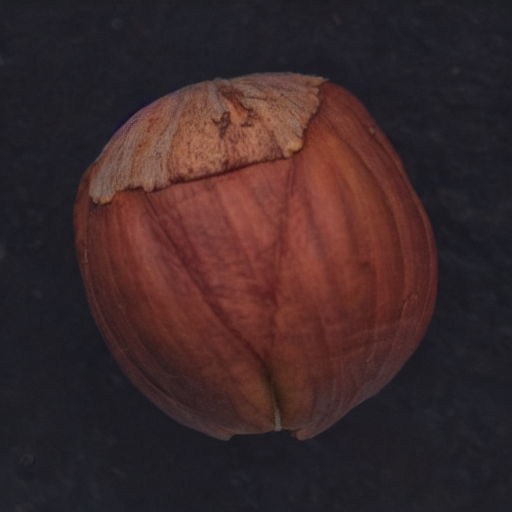

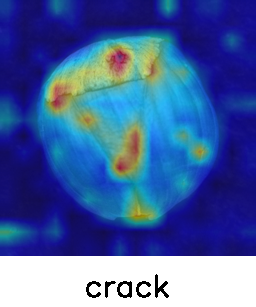

  0%|          | 0/200 [00:00<?, ?it/s]

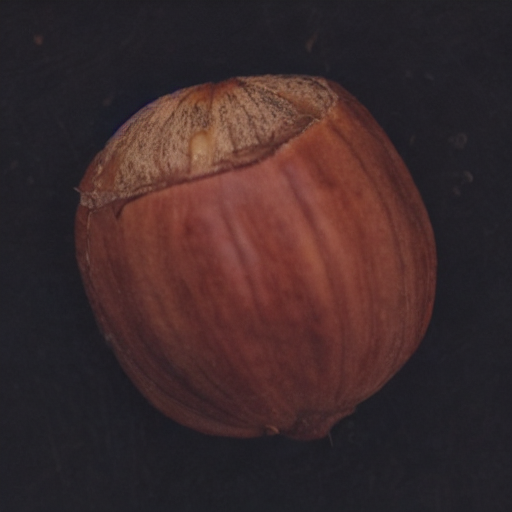

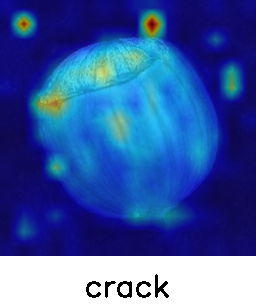

  0%|          | 0/200 [00:00<?, ?it/s]

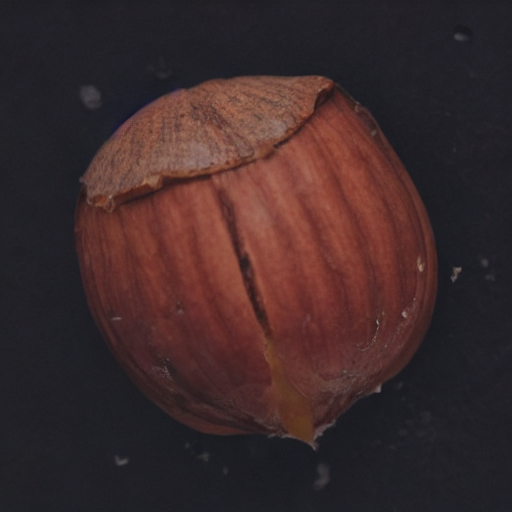

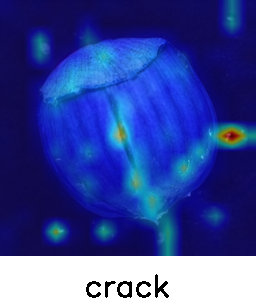

In [10]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000), random.randint(0, 100000),random.randint(0, 100000),random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))

    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

**🔎 실행 결과 읽기** (4장, 왼쪽부터 1\~4번)
- `Altering tokens: ['crack']` → 집중 대상이 맞게 잡혔다.
- **2번, 4번**: 껍질 위에서 아래로 **갈라진 금**이 뚜렷하다. 주의 맵도 그 금을 따라 밝게 나타난다.
- **1번**: 헤이즐넛에는 금이 뚜렷하지 않고, 대신 **배경 오른쪽 위에 검은 부스러기** 같은 것이 생겼다. 주의도 헤이즐넛보다 배경의 점 몇 개에 흩어져 있다.
- **3번**: 정상 사진과 거의 같아 균열이 잘 보이지 않는다.
- 4장 모두 헤이즐넛의 크기와 위치, 꼭지 모양이 정상 사진과 조금씩 다르다. 사진 전체를 다시 그리기 때문이다(`mask_image=None`).

**💡 생각해 볼 점**
- 시드에 따라 결과가 크게 달라서, 4장 중 쓸 만한 균열은 2장이었다. 결함 데이터로 쓰려면 **많이 만든 뒤 골라내는 과정**이 필요하다.
- 주의 맵이 물체 밖(배경)에 몰리면 결함도 엉뚱한 곳에 생긴다(1번). `mask_image`로 물체 영역을 지정하면 이런 실패를 줄일 수 있다(저장소에 `example_image/fg_mask/000.png`라는 헤이즐넛 전경 마스크가 들어 있다).

> ✍️ **내 코멘트**
>
> 시드 4개로 균열이 생긴 헤이즐넛을 만들었더니 2장은 그럴듯한 금이 생겼고, 나머지는 배경에 엉뚱한 자국이 생기거나 거의 그대로였다. 결함 생성은 매번 성공하지 않으므로 많이 만들어 골라내거나 마스크로 위치를 잡아 줘야 한다는 것을 알게 됐다.

# 파트 D. PCB: 균열(crack)

## 흐름 10. PCB 프롬프트와 정상 이미지
전자 기판(PCB) 사진에 같은 "균열" 문장을 적용한다.

**📖 코드 설명**
- 문장은 헤이즐넛과 같고 물체 이름만 `pcb`다. `crack`이 여전히 8번이다.
- `image_guidance_path = 'normal.png'`: 저장소에 없는 파일이다. 원본 노트북 출력에 남은 사진(VisA 데이터셋의 PCB로 보임)을 저장해 코랩에 올렸다.
- ☁️ `show()` → `display()`

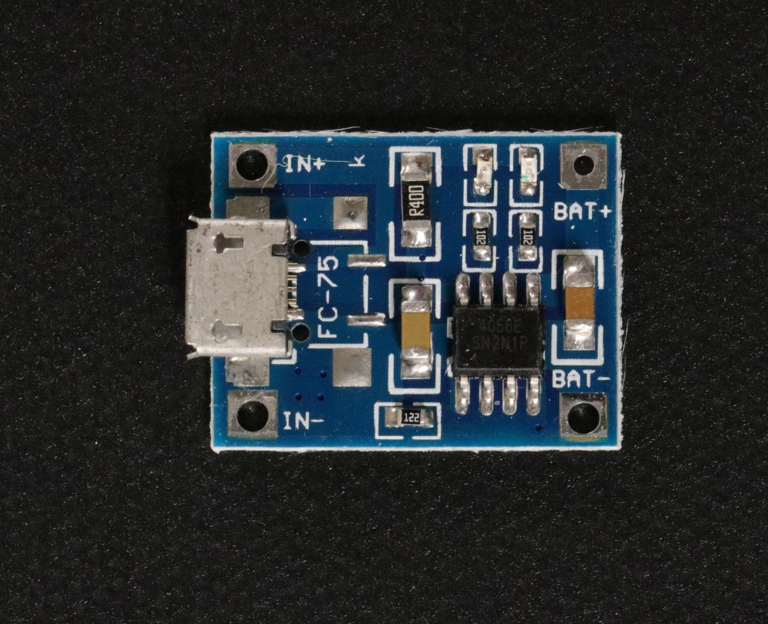

In [11]:
from PIL import Image

type = "pcb"
tokens = "8"
prompt = f"a photo of a {type} with a crack on it"
normal_prompt = f"a photo of a {type}"
detailed_prompt = f"a photo of a {type} with a large, jagged crack exposing the interior."

image_guidance_path = 'normal.png'


image_guidance = Image.open(image_guidance_path).convert("RGB")
original_size = image_guidance.size
image_guidance.thumbnail((768, 768))
# 📄 원본: image_guidance.show()
# ☁️ 코랩용: 코랩에서는 PIL의 show()가 셀 아래에 이미지를 띄우지 않아서 display()로 바꿈
display(image_guidance)

**💡 생각해 볼 점**
- 이미지 경로가 `'normal.png'` 하나뿐이라, 이 파일이 없는 환경에서는 실행되지 않는다. 실습 자료로 쓰려면 필요한 파일을 저장소 안 경로(예: `example_image/`)에 함께 두거나 받는 방법을 적어 둬야 한다.
- 사진이 768×624로 정사각형이 아니다. 생성할 때 512×512로 바꿔 넣으므로 가로가 더 많이 줄어들어, 기판이 원래보다 세로로 조금 길쭉해진다.

> ✍️ **내 코멘트**
>
> 저장소에 없는 `normal.png`는 원본 노트북 출력에 남은 사진으로 대신했다. 실습 코드가 다른 환경에서도 돌려면 필요한 입력 파일까지 함께 챙겨야 한다는 것을 알게 됐다.

## 흐름 11. PCB 결함 이미지 4장 생성
시드 4개로 균열이 생긴 PCB를 4장 만든다. 코드는 흐름 9와 같다.

**📖 코드 설명**
- 흐름 9와 같은 반복문이다. 문장의 물체 이름만 `pcb`다.

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'pcb',
 6: 'with',
 7: 'a',
 8: 'crack',
 9: 'on',
 10: 'it'}
Altering tokens: ['crack']


  0%|          | 0/200 [00:00<?, ?it/s]

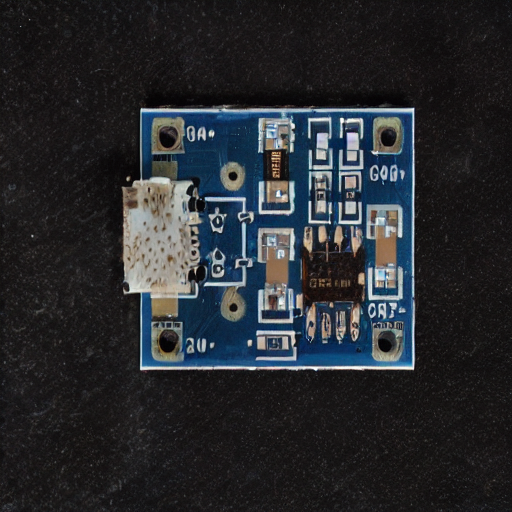

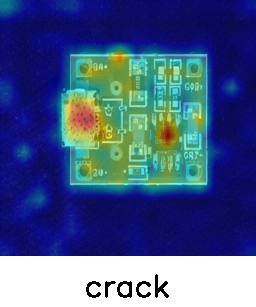

  0%|          | 0/200 [00:00<?, ?it/s]

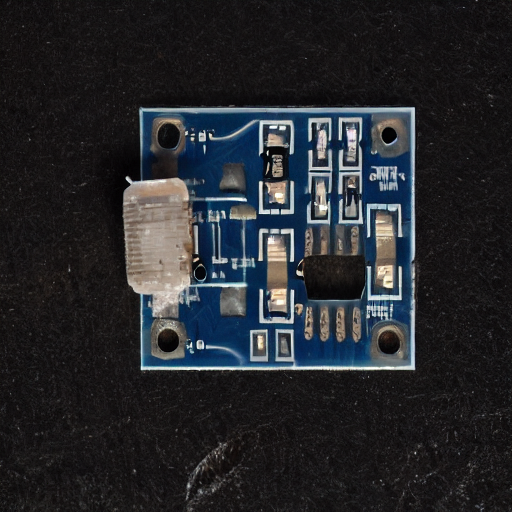

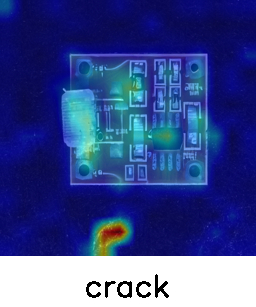

  0%|          | 0/200 [00:00<?, ?it/s]

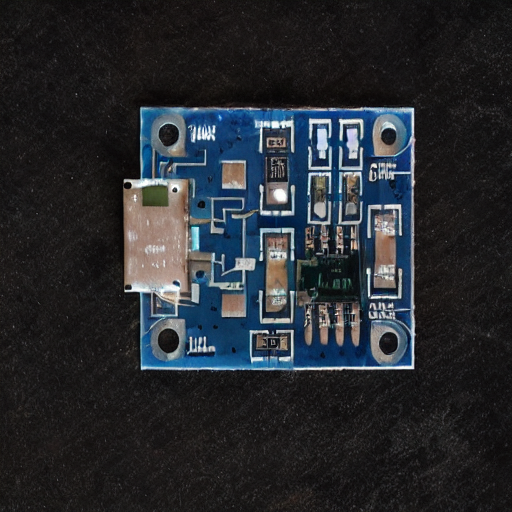

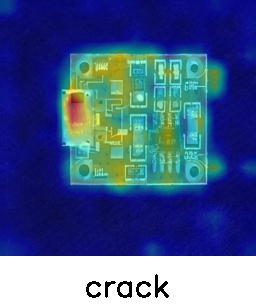

  0%|          | 0/200 [00:00<?, ?it/s]

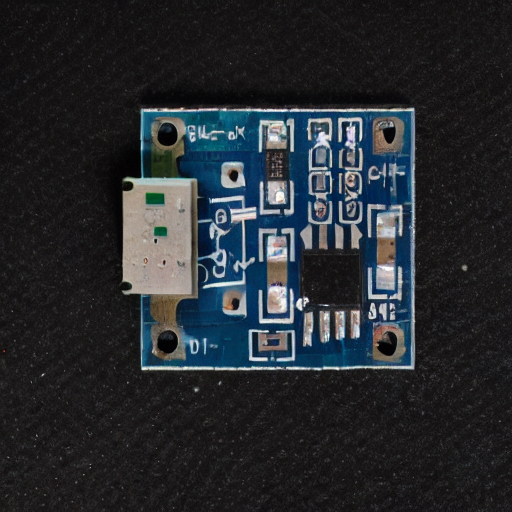

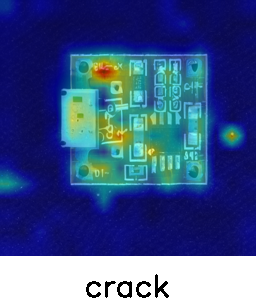

In [12]:
import random
from run import get_indices_to_alter_new
import time

seeds = [random.randint(0, 100000), random.randint(0, 100000),random.randint(0, 100000),random.randint(0, 100000)]

token_indices = get_indices_to_alter_new(stable, prompt, tokens)


compute_time = []
for seed in seeds:
    g = torch.Generator('cuda').manual_seed(seed)
    prompts = [prompt]
    controller = AttentionStore()

    start_time = time.time()
    image, image_latent = run_and_display(prompts=prompts,
                            controller=controller,
                            indices_to_alter=token_indices,
                            # init_image=None,
                            init_image=image_guidance,
                            init_image_guidance_scale=0.3,
                            mask_image=None,
                            generator=g,
                            run_standard_sd=False,
                            display_output=True,
                            scale_factor=50,
                            normal_prompt=normal_prompt,
                            detailed_prompt=detailed_prompt,)
    # print("--- %s seconds ---" % (time.time() - start_time))
    compute_time.append((time.time() - start_time))

    attention_images=vis_utils.show_cross_attention(attention_store=controller,
                                   prompt=prompt,
                                   tokenizer=tokenizer,
                                   res=16,
                                   from_where=("up", "down", "mid"),
                                   indices_to_alter=token_indices,
                                   orig_image=image)

**🔎 실행 결과 읽기** (원본 셀 4장, 왼쪽부터 1\~4번)
- 기판을 가로지르는 **선 모양의 균열은 4장 모두 나오지 않았다.**
- 대신 바뀐 곳: 1번은 USB 커넥터 표면이 부식된 것처럼 얼룩덜룩해졌고, 3번은 커넥터가 일그러졌다. 주의 맵도 이 두 장에서 **커넥터 쪽에 빨갛게** 몰려 있다.
- 2번은 주의가 **기판 아래 배경**에 몰렸고, 바로 그 자리 바닥에 휘어진 긁힘 자국이 생겼다. 균열이 기판이 아니라 바닥에 생긴 셈이다.
- 4장 모두 실크 인쇄 글자(`IN+`, `BAT+` 등)가 알아볼 수 없는 글자로 바뀌고, 부품 배치와 배선도 조금씩 다시 그려졌다.

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'pcb',
 6: 'with',
 7: 'a',
 8: 'missing',
 9: 'component'}
Altering tokens: ['missing']

[missing] seed = 0


100%|████████████████████████████████████████| 890M/890M [00:03<00:00, 275MiB/s]
100%|████████████████████████████████████████| 244M/244M [00:01<00:00, 162MiB/s]
/content/AnomalyAny/clip_pipeline_attend_and_excite.py:712: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  num_channels_latents = self.unet.in_channels


  0%|          | 0/200 [00:00<?, ?it/s]

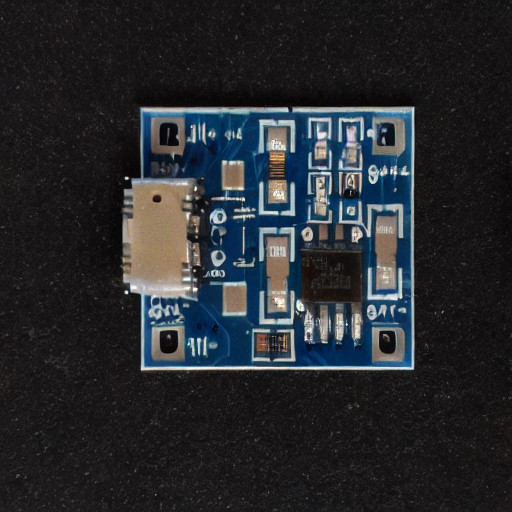

[missing] seed = 0 생성 시간: 197초


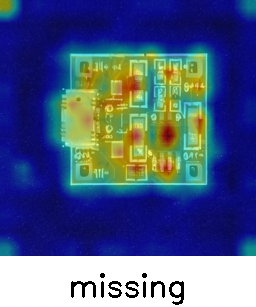


[missing] seed = 1


  0%|          | 0/200 [00:00<?, ?it/s]

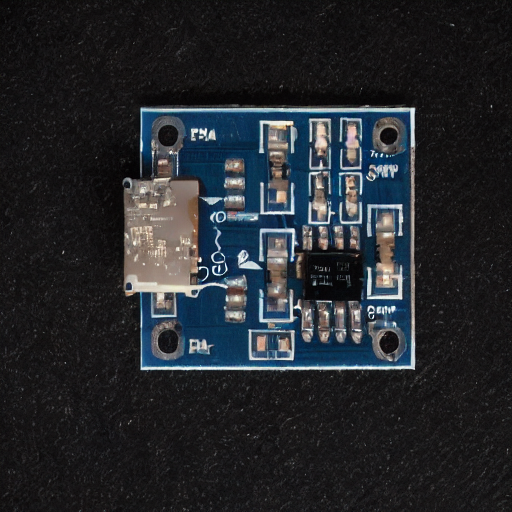

[missing] seed = 1 생성 시간: 189초


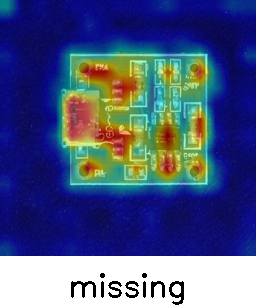

{1: 'a',
 2: 'photo',
 3: 'of',
 4: 'a',
 5: 'pcb',
 6: 'with',
 7: 'a',
 8: 'burnt',
 9: 'mark',
 10: 'on',
 11: 'it'}
Altering tokens: ['burnt']

[burnt] seed = 0


  0%|          | 0/200 [00:00<?, ?it/s]

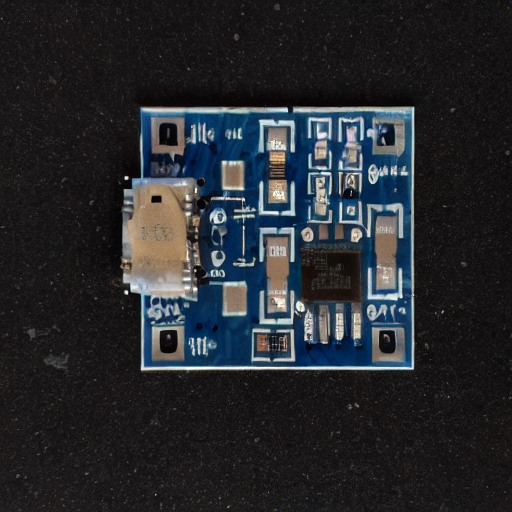

[burnt] seed = 0 생성 시간: 188초


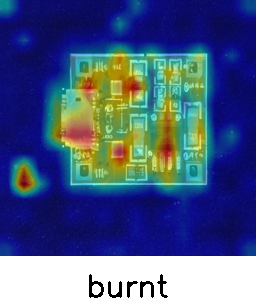


[burnt] seed = 1


  0%|          | 0/200 [00:00<?, ?it/s]

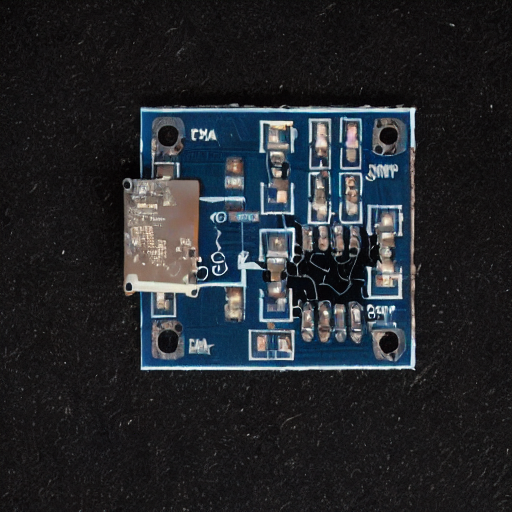

[burnt] seed = 1 생성 시간: 187초


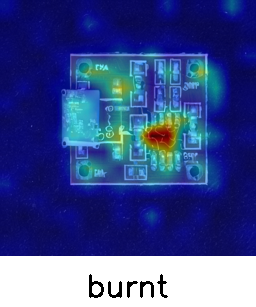

In [10]:
# 🧪 [개인 실험] 원본에 없는 셀: crack 문장으로는 PCB에 균열이 생기지 않아서, PCB에 실제로 생기는 결함(부품 누락, 탄 자국)을 문장으로 주면 그럴듯해지는지 궁금했다
import time
from run import get_indices_to_alter_new

exp_prompts = {
    "missing": ("a photo of a pcb with a missing component",
                "a photo of a pcb with a missing component, leaving bare solder pads on the board."),
    "burnt": ("a photo of a pcb with a burnt mark on it",
              "a photo of a pcb with a dark, charred burn mark on the board surface."),
}
exp_seeds = [0, 1]  # 같은 그림을 다시 만들 수 있게 시드를 고정하고 출력한다

for name, (exp_prompt, exp_detailed) in exp_prompts.items():
    exp_indices = get_indices_to_alter_new(stable, exp_prompt, "8")  # 두 문장 모두 8번째 단어가 결함 단어
    for seed in exp_seeds:
        print(f"\n[{name}] seed = {seed}")
        g = torch.Generator('cuda').manual_seed(seed)
        controller = AttentionStore()
        start_time = time.time()
        image, image_latent = run_and_display(prompts=[exp_prompt],
                                              controller=controller,
                                              indices_to_alter=exp_indices,
                                              init_image=image_guidance,
                                              init_image_guidance_scale=0.3,
                                              mask_image=None,
                                              generator=g,
                                              run_standard_sd=False,
                                              display_output=True,
                                              scale_factor=50,
                                              normal_prompt=normal_prompt,
                                              detailed_prompt=exp_detailed)
        print(f"[{name}] seed = {seed} 생성 시간: {time.time() - start_time:.0f}초")
        vis_utils.show_cross_attention(attention_store=controller,
                                       prompt=exp_prompt,
                                       tokenizer=tokenizer,
                                       res=16,
                                       from_where=("up", "down", "mid"),
                                       indices_to_alter=exp_indices,
                                       orig_image=image)

**🔎 개인 실험 1 결과 읽기** (문장 2개 × 시드 0, 1)
- 토큰 번호표에서 두 문장 모두 8번이 결함 단어(`missing`, `burnt`)로 잡혔다. 1장에 187\~197초 걸렸다.
- **burnt, 시드 1**: IC 주변이 **까맣게 탄 듯한 자국**으로 덮였고, `burnt`의 주의 맵이 빨갛게 몰린 자리와 같다. 이번 실습에서 처음으로 기판 위에 결함다운 결함이 생겼다.
- **missing, 시드 0**: 정상 사진에서 황갈색 부품(커패시터)이 있던 자리가 은색 **빈 패드**로 바뀌어, 부품이 빠진 것처럼 보인다. 주의는 한 점이 아니라 기판의 부품들 위에 넓게 퍼져 있다.
- **missing, 시드 1**과 **burnt, 시드 0**: 부품 배치가 다시 그려졌을 뿐 결함이라고 할 만한 곳이 뚜렷하지 않다. burnt 시드 0은 주의가 커넥터와 기판 왼쪽 아래 배경에 몰렸다.
- 같은 시드끼리는 문장이 달라도 **기판 모양이 거의 같았다.** 전체 모습은 시드(노이즈)가, 결함이 생기는 자리는 결함 단어의 주의가 정한다.

pcb4 학습(실제 정상) 804장 / 테스트 실제 정상 201장, 실제 불량 100장
VisA pcb4 원본 사진 크기: (1358, 1104)
VisA pcb4 테스트 AUROC: 0.9824, 참고 임계값(F1 최고): 23.84
  실제 정상 점수: 최소 11.82 / 중앙값 17.29 / 최대 35.51
  실제 불량 점수: 최소 21.25 / 중앙값 31.70 / 최대 64.53

이미지                      이상 점수   판정(임계값 23.84)
normal_orig              14.69   정상
normal_512               14.58   정상
vae_recon                19.18   정상
burnt_seed0              35.01   불량
burnt_seed1              42.17   불량
crack_1                  32.77   불량
crack_2                  36.02   불량
crack_3                  34.77   불량
crack_4                  35.64   불량
missing_seed0            30.38   불량
missing_seed1            31.96   불량


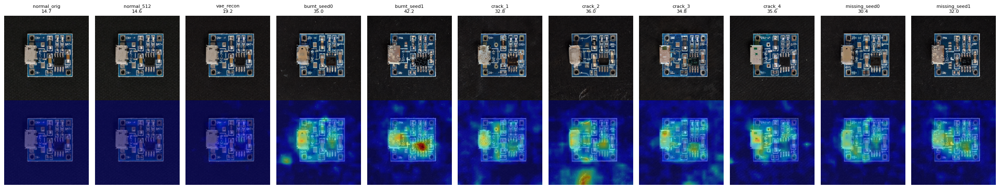

In [6]:
# 🧪 [개인 실험] 원본에 없는 셀: 생성한 결함 이미지를 사람 대신 AI가 먼저 걸러 줄 수 있는지 궁금해서, 6주차 PaDiM(VisA pcb4 정상으로 학습)에 넣어 이상 점수와 히트맵을 확인했다
# 원본 셀은 생성 이미지를 파일로 저장하지 않아서, 위 두 셀의 출력 이미지 8장을 gen/ 폴더에 올려 두고 읽는다
import os, glob, tarfile, urllib.request
import numpy as np, pandas as pd
import torch.nn.functional as F
import torchvision.models as models
import torchvision.transforms as T
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, precision_recall_curve

# 1) VisA 데이터셋 받기 (6주차와 같은 파일, pcb4 폴더만 푼다)
if not os.path.exists("/content/VisA/pcb4"):
    urllib.request.urlretrieve("https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar", "/content/VisA.tar")
    with tarfile.open("/content/VisA.tar") as tar:
        members = [m for m in tar.getmembers() if m.name.lstrip("./").startswith("pcb4/")]
        tar.extractall("/content/VisA", members=members, filter="data")

df = pd.read_csv("/content/VisA/pcb4/image_anno.csv")
normal_df, anomaly_df = df[df.label == "normal"], df[df.label != "normal"]
n_train = int(len(normal_df) * 0.8)  # 6주차와 같은 8:2 나누기 (앞 80%로 학습)
train_paths = ["/content/VisA/" + p for p in normal_df.image[:n_train]]
test_paths = ["/content/VisA/" + p for p in list(normal_df.image[n_train:]) + list(anomaly_df.image)]
test_labels = np.array([0] * (len(normal_df) - n_train) + [1] * len(anomaly_df))
print(f"pcb4 학습(실제 정상) {len(train_paths)}장 / 테스트 실제 정상 {(test_labels == 0).sum()}장, 실제 불량 {(test_labels == 1).sum()}장")
print("VisA pcb4 원본 사진 크기:", Image.open(train_paths[0]).size)

# 2) PaDiM: 6주차 흐름 14·20과 같은 설정 (wide_resnet50의 layer1~3, 256×256, 28×28 패치, 무작위 100차원)
backbone = models.wide_resnet50_2(weights="IMAGENET1K_V1").to(device).eval()
tf = T.Compose([T.Resize((256, 256)), T.ToTensor(), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
torch.manual_seed(0)
proj = F.normalize(torch.randn(256 + 512 + 1024, 100, device=device), dim=0)

def embed(items, bs=32):
    """사진(경로 또는 PIL) 목록 -> 패치별 특징 [N, 784, 100]"""
    out = []
    for i in range(0, len(items), bs):
        imgs = [Image.open(p) if isinstance(p, str) else p for p in items[i:i + bs]]
        x = torch.stack([tf(im.convert("RGB")) for im in imgs]).to(device)
        feats = []
        hooks = [getattr(backbone, l).register_forward_hook(lambda m, a, o: feats.append(o)) for l in ("layer1", "layer2", "layer3")]
        with torch.no_grad():
            backbone(x)
        for h in hooks:
            h.remove()
        f = torch.cat([F.adaptive_avg_pool2d(t, (28, 28)) for t in feats], dim=1)  # [n, 1792, 28, 28]
        out.append((f.permute(0, 2, 3, 1).reshape(len(imgs), 784, -1) @ proj).cpu())
    return torch.cat(out)  # 통계와 거리 계산은 CPU에서 한다 (GPU 배치 행렬곱에서 CUBLAS_STATUS_NOT_INITIALIZED 에러가 남)

train_emb = embed(train_paths)
mean = train_emb.mean(0)  # 패치 위치마다 정상의 평균 [784, 100]
cen = (train_emb - mean).permute(1, 0, 2)  # [784, N, 100]
inv_cov = torch.linalg.inv(cen.transpose(1, 2) @ cen / (len(train_emb) - 1) + 1e-4 * torch.eye(100))

def score_maps(emb):
    """패치마다 마할라노비스 거리 -> [N, 28, 28]"""
    d = (emb - mean).permute(1, 0, 2)  # [784, N, 100]
    m = ((d @ inv_cov) * d).sum(-1).clamp(min=0).sqrt()  # [784, N]
    return m.T.reshape(-1, 28, 28)

# 3) 먼저 PaDiM이 실제 불량을 잘 잡는지 확인하고, 참고용 임계값(F1 최고)을 정한다
test_scores = score_maps(embed(test_paths)).amax(dim=(1, 2)).cpu().numpy()
prec, rec, thr = precision_recall_curve(test_labels, test_scores)
f1 = 2 * prec * rec / (prec + rec + 1e-8)
threshold = thr[np.argmax(f1[:-1])]
print(f"VisA pcb4 테스트 AUROC: {roc_auc_score(test_labels, test_scores):.4f}, 참고 임계값(F1 최고): {threshold:.2f}")
for name, lab in (("실제 정상", 0), ("실제 불량", 1)):
    s = test_scores[test_labels == lab]
    print(f"  {name} 점수: 최소 {s.min():.2f} / 중앙값 {np.median(s):.2f} / 최대 {s.max():.2f}")

# 4) 비교군: normal.png 원본, 512×512로 바꾼 것, 결함 없이 VAE로만 압축·복원한 것, 그리고 생성 이미지 8장
normal_img = Image.open("normal.png").convert("RGB")
with torch.no_grad():
    x = T.ToTensor()(normal_img.resize((512, 512)))[None].to(device) * 2 - 1
    rec_x = stable.vae.decode(stable.vae.encode(x).latent_dist.mean).sample
vae_img = T.ToPILImage()(((rec_x[0].float().clamp(-1, 1) + 1) / 2).cpu())

items = [("normal_orig", normal_img), ("normal_512", normal_img.resize((512, 512))), ("vae_recon", vae_img)]  # 그림 제목에 한글이 깨져서 영어로 적는다
items += [(os.path.basename(p)[:-4], Image.open(p).convert("RGB")) for p in sorted(glob.glob("gen/*.png"))]
maps = score_maps(embed([im for _, im in items]))
scores = maps.amax(dim=(1, 2)).cpu().numpy()

print(f"\n{'이미지':<22}{'이상 점수':>8}   판정(임계값 {threshold:.2f})")
for (name, _), s in zip(items, scores):
    print(f"{name:<22}{s:8.2f}   {'불량' if s > threshold else '정상'}")

# 5) 히트맵: 빨간 곳이 PaDiM이 이상하다고 본 자리
fig, axes = plt.subplots(2, len(items), figsize=(2.2 * len(items), 4.6))
for k, ((name, im), m, s) in enumerate(zip(items, maps, scores)):
    axes[0, k].imshow(im.resize((256, 256)))
    axes[0, k].set_title(f"{name}\n{s:.1f}", fontsize=8)
    heat = F.interpolate(m[None, None], size=(256, 256), mode="bilinear")[0, 0].cpu()
    axes[1, k].imshow(im.resize((256, 256)))
    axes[1, k].imshow(heat, cmap="jet", alpha=0.5, vmin=float(test_scores.min()), vmax=float(scores.max()))
for a in axes.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

**🔎 개인 실험 2 결과 읽기** (6주차 PaDiM으로 채점)
- PaDiM(VisA pcb4 실제 정상 804장으로 학습)은 VisA 테스트에서 AUROC 0.9824로 실제 불량을 잘 가려냈다. 실제 정상은 11.82\~35.51점(중앙값 17.29), 실제 불량은 21.25\~64.53점(중앙값 31.70)이고, 참고 임계값(F1 최고)은 23.84다.
- 대조군은 모두 정상으로 판정됐다: `normal.png` 14.69, 512×512로 바꾼 것 14.58, 결함 없이 SD의 VAE로 압축했다 복원한 것 19.18. 크기를 바꾸거나 VAE를 거친 것만으로는 불량이 되지 않는다.
- 생성 이미지 8장은 **모두 불량**으로 판정됐다(30.38\~42.17점). 눈으로 봐서 결함이 뚜렷하지 않던 burnt 시드 0(35.01), missing 시드 1(31.96), crack 3번(34.77)도 포함이다.
- 히트맵을 보면 burnt 시드 1은 **탄 자국 자리**가 가장 진하게 빨갛고(42.17, 8장 중 최고), crack 2번은 **바닥의 긁힘 자리**가 빨갛다. 결함이 생긴 곳은 정확히 찾았다.
- 하지만 8장 모두 **USB 커넥터 부근**도 노랗거나 빨갛다. 커넥터와 글자는 생성할 때마다 다시 그려지는데(흐름 9·11에서 본 것), PaDiM은 이것도 "평소와 다르다"고 본다.

**💡 생각해 볼 점**
- 헤이즐넛에 비해 PCB는 같은 `crack` 문장으로도 결과가 문장과 거리가 멀었다. 같은 단어라도 물체에 따라 SD가 떠올리는 모습이 다르니, 그 물체에 실제로 생기는 결함을 문장으로 고르는 것이 중요하다.
- 글자와 미세 배선이 뭉개지는 것은 원본 셀 4장과 실험 1의 4장 모두에서 똑같이 나타났다. 이런 이미지를 그대로 불량 데이터로 쓰면 이상 탐지 모델이 원래 결함이 아니라 **생성 과정의 흔적**을 배울 위험이 있다.
- `crack`은 원본 셀 4장 중 기판 위에 결함이 생긴 것이 없었지만, PCB에 맞는 문장으로는 4장 중 2장(탄 자국 1장, 부품 누락 1장)이 결함처럼 보였다. 다만 원본 셀의 시드는 출력되지 않아 같은 시드로 비교한 것은 아니고, 장수도 적어서 "문장 때문"이라고 단정할 수는 없다.
- 왜 결함이 안 보이는 그림까지 불량일까? 대조군(VAE 복원 19.18)이 정상으로 나왔으니 압축 자체가 원인은 아니고, 디노이징 60스텝 동안 기판이 **다시 그려진 흔적**(커넥터, 글자, 배선)이 원인으로 보인다. PaDiM은 "진짜 정상과 다른 곳"을 찾는 모델이라, 그것이 의도한 결함인지 생성의 흔적인지는 구분하지 못한다.
- 그래서 PaDiM만으로 "쓸 만한 결함 이미지"를 자동으로 고를 수는 없었다. 대신 히트맵이 결함 자리를 정확히 가리키는 경우(burnt 시드 1, crack 2번)가 있어서, 사람이 볼 곳을 알려 주는 1차 도구로는 쓸 수 있다.

> ✍️ **내 코멘트**
>
> PCB에 균열 문장을 넣었더니 금이 간 기판 대신 커넥터가 망가지거나 글자·배선이 뭉개졌다. 개인 실험으로 "탄 자국", "부품 누락"처럼 PCB에 실제로 생기는 결함을 문장으로 주니 4장 중 2장이 결함처럼 보여서, 물체에 맞는 결함 문장을 고르는 것이 중요하다는 것을 알게 됐다. 6주차 PaDiM으로 채점해 보니 생성 이미지 8장이 모두 불량으로 판정됐는데, 결함 자리뿐 아니라 다시 그려진 커넥터에도 반응해서, PaDiM은 결함과 생성 흔적을 구분하지 못한다는 것을 알게 됐다.